# 03 · t-SNE des profils IgE

La PCA a montré que la variance est dominée par un axe d'**intensité** (nombre et niveau des IgE), puis se disperse sur beaucoup de composantes. On teste ici une méthode **non linéaire**, t-SNE, pour voir si des groupes de patients apparaissent.

**Ce que fait t-SNE** : il place les patients en 2D de façon à ce que les patients **proches** dans l'espace d'origine restent proches sur la carte. Il préserve le voisinage local, pas les distances globales.

**Précautions de lecture** (importantes) :
- la **distance entre deux groupes** sur la carte ne veut rien dire, seule l'appartenance à un même voisinage compte ;
- la **taille** d'un groupe sur la carte ne reflète pas sa dispersion réelle ;
- t-SNE peut **fabriquer des groupes** visuels à partir de données continues : un amas n'est pas une preuve de cluster ;
- le résultat dépend du paramètre **perplexité** (taille du voisinage considéré, environ le nombre de voisins) et de la graine aléatoire.

On s'en sert donc comme **outil de visualisation**, pas comme méthode de clustering.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors

from acc.data import load_raw, split_columns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 70

CHIPS = ["ISAC_V1", "ISAC_V2", "ALEX"]
THRESHOLD = 0.3
SEED = 0
K = 15  # neighbourhood size for the quantitative checks

# sklearn casts the binary matrix to bool for the Jaccard metric: harmless
warnings.filterwarnings("ignore", message="Data was converted to boolean")

## 1. Préparation

Comme pour la PCA : une matrice par puce, avec les allergènes de cette puce, en `log1p`. Les patients avec une mesure invalide (valeur `-1` dans le brut) sont exclus.

In [2]:
df = load_raw()
clinical_cols, ige_cols = split_columns(df)

raw = {}  # chip -> raw IgE matrix (patients x allergens of that chip)
for chip in CHIPS:
    g = df[df["Chip_Type"] == chip]
    cols = [c for c in ige_cols if g[c].notna().mean() > 0.5]
    raw[chip] = g.loc[g[cols].notna().all(axis=1), cols]

n_positive = {chip: (raw[chip] >= THRESHOLD).sum(axis=1) for chip in CHIPS}
for chip in CHIPS:
    print(f"{chip:8s}: {raw[chip].shape[0]:4d} patients x {raw[chip].shape[1]} allergens, "
          f"{(n_positive[chip] == 0).mean():.0%} with no positive allergen")

ISAC_V1 : 2350 patients x 112 allergens, 13% with no positive allergen
ISAC_V2 :  746 patients x 112 allergens, 28% with no positive allergen
ALEX    : 1139 patients x 223 allergens, 18% with no positive allergen


### Une étiquette « profil dominant » pour colorer les cartes

Pour lire les cartes, on donne à chaque patient une étiquette simple, calculée **uniquement à partir de ses IgE** : le groupe de marqueurs pour lequel il a l'IgE moyenne la plus élevée. On ne garde que des marqueurs présents sur les trois puces.

C'est une aide à la lecture, pas une classification clinique : un patient polysensibilisé reçoit un seul groupe.

In [3]:
MARKERS = {
    "mites": ["Der_p_1", "Der_p_2"],
    "grass pollen": ["Phl_p_1"],
    "PR-10 (birch)": ["Bet_v_1", "Mal_d_1", "Ara_h_8"],
    "cypress / olive": ["Cup_a_1", "Ole_e_1"],
    "weeds": ["Art_v_1", "Amb_a_1"],
    "cat / dog": ["Fel_d_1", "Can_f_1"],
    "mold": ["Alt_a_1"],
    "nuts / LTP": ["Ara_h_2", "Jug_r_1", "Pru_p_3"],
    "egg / milk": ["Gal_d_1", "Bos_d_8"],
    "shellfish": ["Pen_m_1"],
}
GROUP_ORDER = list(MARKERS) + ["none"]
PALETTE = dict(zip(GROUP_ORDER, sns.color_palette("tab10", 10) + [(0.8, 0.8, 0.8)]))


def dominant_group(ige):
    """Marker group with the highest mean log1p IgE, or 'none' if no marker is positive."""
    scores = pd.DataFrame({k: np.log1p(ige[v]).mean(axis=1) for k, v in MARKERS.items()})
    any_positive = pd.concat([ige[v] >= THRESHOLD for v in MARKERS.values()], axis=1).any(axis=1)
    return scores.idxmax(axis=1).where(any_positive, "none")


group = {chip: dominant_group(raw[chip]) for chip in CHIPS}
pd.DataFrame({chip: group[chip].value_counts(normalize=True).mul(100).round(1)
              for chip in CHIPS}).reindex(GROUP_ORDER)

,ISAC_V1,ISAC_V2,ALEX
mites,21.0,22.0,16.1
grass pollen,23.6,18.1,24.8
PR-10 (birch),4.8,6.7,5.2
cypress / olive,12.4,0.7,3.2
weeds,0.9,1.7,2.5
cat / dog,5.8,4.2,4.9
mold,6.4,5.2,6.8
nuts / LTP,3.1,2.8,3.4
egg / milk,2.5,1.7,1.5
shellfish,2.3,3.4,2.0


Petite fonction utilitaire pour tracer une carte colorée :

In [4]:
def plot_map(ax, emb, color, title, categorical):
    if categorical:
        for g in GROUP_ORDER:
            mask = (color == g).values
            if mask.any():
                ax.scatter(emb[mask, 0], emb[mask, 1], s=4, color=PALETTE[g], label=g)
    else:
        sc = ax.scatter(emb[:, 0], emb[:, 1], s=4, c=color, cmap="viridis")
        plt.colorbar(sc, ax=ax, label="n positive")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

Pour ne pas juger les cartes uniquement à l'œil, on utilise deux mesures, toujours sur les **15 plus proches voisins** de chaque patient :
- la **trustworthiness** (entre 0 et 1) : les voisins sur la carte étaient-ils déjà voisins dans l'espace d'origine ? Elle vaut 1 si la carte n'invente aucun voisinage ;
- l'**accord d'étiquette** : la part des voisins qui ont le même profil dominant que le patient. On la compare à ce qu'on obtiendrait **par hasard** (somme des carrés des proportions des groupes) et à la même mesure **dans l'espace d'origine**.

In [5]:
def knn_agreement(x, labels, metric="euclidean"):
    """Share of each point's K nearest neighbours that carry the same label."""
    nn = NearestNeighbors(n_neighbors=K + 1, metric=metric).fit(x)
    idx = nn.kneighbors(x, return_distance=False)[:, 1:]  # drop the point itself
    labels = np.asarray(labels)
    return (labels[idx] == labels[:, None]).mean()


def chance_agreement(labels):
    """Expected agreement if neighbours were drawn at random."""
    return (pd.Series(labels).value_counts(normalize=True) ** 2).sum()

## 2. t-SNE sur les niveaux d'IgE (distance euclidienne)

Premier essai, le plus direct : t-SNE sur les IgE en `log1p`, distance euclidienne, perplexité 30 (valeur par défaut).

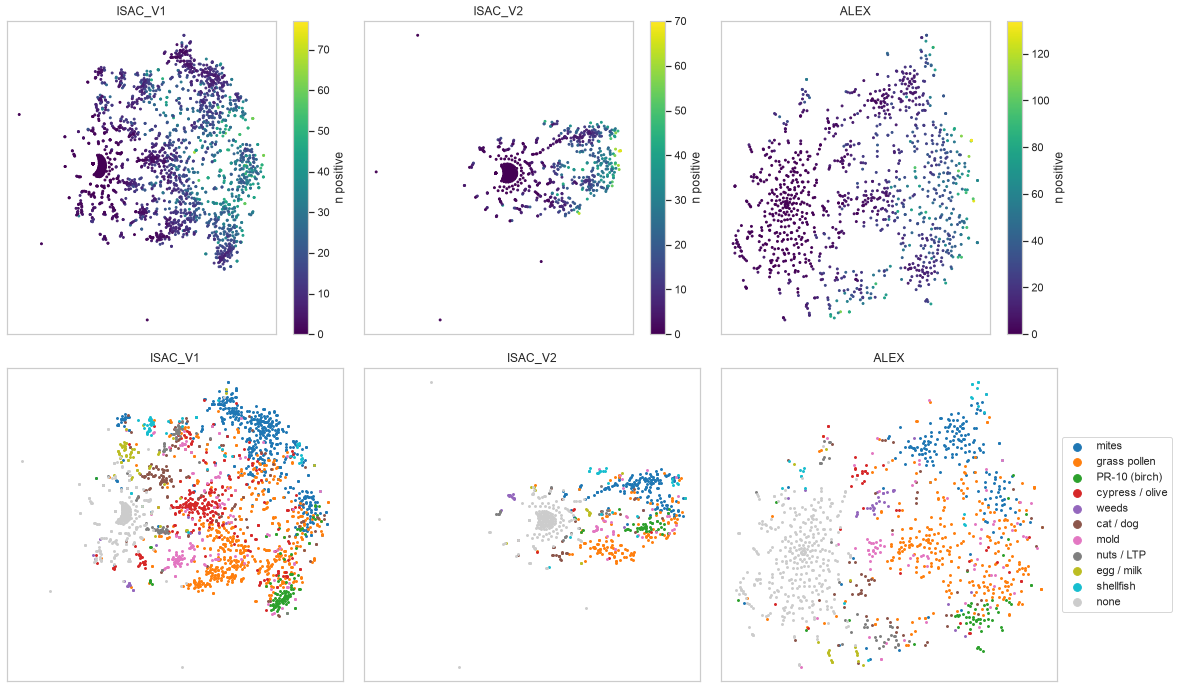

In [6]:
emb_euclid = {}
for chip in CHIPS:
    tsne = TSNE(perplexity=30, init="pca", random_state=SEED)
    emb_euclid[chip] = tsne.fit_transform(np.log1p(raw[chip]))

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for j, chip in enumerate(CHIPS):
    plot_map(axes[0, j], emb_euclid[chip], n_positive[chip], chip, categorical=False)
    plot_map(axes[1, j], emb_euclid[chip], group[chip], chip, categorical=True)
axes[1, 2].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4)
plt.tight_layout()
plt.show()

**Lecture.** La carte est organisée d'abord par l'**intensité** : le nombre d'allergènes positifs croît d'un bord à l'autre (ligne du haut). Les patients sans aucun allergène positif s'écrasent en un croissant compact sur ISAC (leurs valeurs sont toutes à 0, donc identiques) et en un nuage diffus sur ALEX (qui rapporte des petites valeurs sous le seuil). Les profils (ligne du bas) sont visibles, mais restent au second plan derrière ce gradient, comme dans la PCA.

## 3. t-SNE sur la *forme* du profil (distance cosinus)

Avec la distance euclidienne, deux patients sensibilisés aux mêmes allergènes mais à des niveaux différents sont éloignés : l'intensité risque encore de dominer, comme dans la PCA.

La **distance cosinus** ne regarde que la **direction** du vecteur d'IgE, c'est-à-dire *à quoi* le patient est sensibilisé, et pas *à quel point*. Deux choix supplémentaires :
- on met à 0 les valeurs sous le seuil de positivité (0,3), pour retirer le bruit des petites valeurs (surtout sur ALEX) ;
- on retire les patients sans aucun allergène positif : leur profil est vide, la notion de direction n'a pas de sens pour eux.

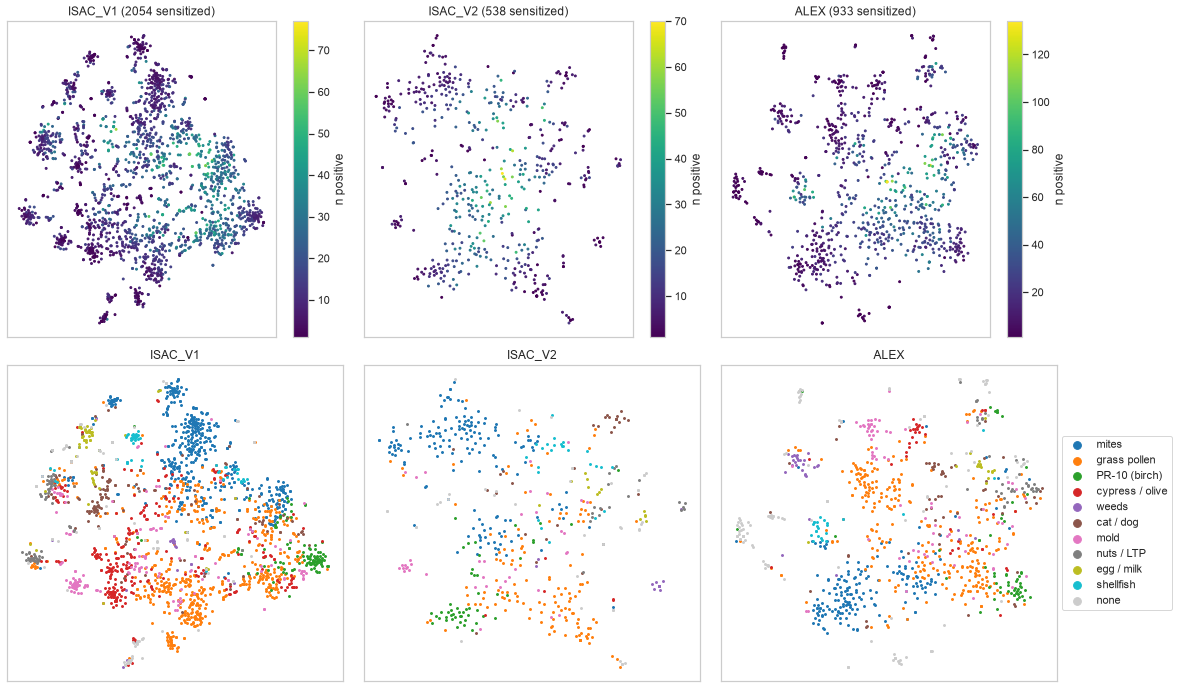

In [7]:
def profile_matrix(ige):
    """log1p IgE with sub-threshold values set to 0, sensitized patients only."""
    x = np.log1p(ige.where(ige >= THRESHOLD, 0))
    return x[(ige >= THRESHOLD).any(axis=1)]


profiles = {chip: profile_matrix(raw[chip]) for chip in CHIPS}

emb_cos = {}
for chip in CHIPS:
    tsne = TSNE(perplexity=30, metric="cosine", init="pca", random_state=SEED)
    emb_cos[chip] = tsne.fit_transform(profiles[chip])

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for j, chip in enumerate(CHIPS):
    idx = profiles[chip].index
    plot_map(axes[0, j], emb_cos[chip], n_positive[chip][idx], f"{chip} ({len(idx)} sensitized)",
             categorical=False)
    plot_map(axes[1, j], emb_cos[chip], group[chip][idx], chip, categorical=True)
axes[1, 2].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4)
plt.tight_layout()
plt.show()

**Lecture.** Le gradient d'intensité n'organise plus la carte. On voit deux régimes :
- des **îlots compacts en périphérie**, presque tous de patients avec **peu** d'allergènes positifs (couleur sombre en haut) et un profil « pur » : acariens, PR-10 (bouleau), moisissures, chat/chien, crustacés, œuf/lait, fruits à coque/LTP ;
- une **grande zone centrale** de patients **polysensibilisés** (couleur plus claire), où graminées, acariens et cyprès/olivier se mélangent progressivement : un continuum plutôt que des groupes séparés.

Les patients aux profils identiques expliquent une partie des petits îlots très serrés : leur distance cosinus est quasi nulle, t-SNE les superpose.

In [8]:
pd.DataFrame({
    chip: {
        "sensitized patients": len(profiles[chip]),
        "share with an identical positive set": (raw[chip].loc[profiles[chip].index] >= THRESHOLD)
        .duplicated(keep=False).mean().round(2),
    }
    for chip in CHIPS
})

,ISAC_V1,ISAC_V2,ALEX
sensitized patients,2054.00,538.00,933.00
share with an identical positive set,0.11,0.12,0.09


## 4. Est-ce robuste ?

### 4.1 Graine aléatoire et choix de la distance

Avec `init="pca"`, t-SNE part toujours du même point et donne presque la même carte quelle que soit la graine : ce n'est pas un vrai test de stabilité. On relance donc avec une **initialisation aléatoire**, sur **5 graines**, pour les deux distances. Pour comparer à armes égales, la version euclidienne est calculée ici sur les mêmes patients sensibilisés.

In [9]:
SEEDS = range(5)
rows, seed_maps = [], {}
for chip in CHIPS:
    idx = profiles[chip].index
    labels = group[chip][idx].values
    spaces = {"euclidean": (np.log1p(raw[chip].loc[idx]).to_numpy(), "euclidean"),
              "cosine": (profiles[chip].to_numpy(), "cosine")}
    for name, (x, metric) in spaces.items():
        for seed in SEEDS:
            emb = TSNE(perplexity=30, metric=metric, init="random",
                       random_state=seed).fit_transform(x)
            if chip == "ISAC_V1" and name == "cosine":
                seed_maps[seed] = emb
            rows.append({"chip": chip, "distance": name, "seed": seed,
                         "trustworthiness": trustworthiness(x, emb, n_neighbors=K, metric=metric),
                         "agreement (map)": knn_agreement(emb, labels),
                         "agreement (original space)": knn_agreement(x, labels, metric),
                         "agreement (chance)": chance_agreement(labels)})

robustness = pd.DataFrame(rows)
summary = robustness.drop(columns="seed").groupby(["chip", "distance"]).agg(["mean", "std"])
summary.round(3)

trustworthiness        agreement (map)         \
                             mean    std            mean    std   
chip    distance                                                  
ALEX    cosine              0.936  0.002           0.600  0.004   
        euclidean           0.867  0.002           0.580  0.005   
ISAC_V1 cosine              0.957  0.002           0.622  0.004   
        euclidean           0.903  0.001           0.604  0.003   
ISAC_V2 cosine              0.912  0.003           0.564  0.006   
        euclidean           0.867  0.003           0.564  0.005   

                  agreement (original space)      agreement (chance)       
                                        mean  std               mean  std  
chip    distance                                                           
ALEX    cosine                         0.613  0.0              0.169  0.0  
        euclidean                      0.635  0.0              0.169  0.0  
ISAC_V1 cosine                         0.669  0.0              0.169  0.0  
        euclidean                      0.655  0.0              0.169  0.0  
ISAC_V2 cosine                         0.611  0.0              0.184  0.0  
        euclidean                      0.584  0.0              0.184  0.0

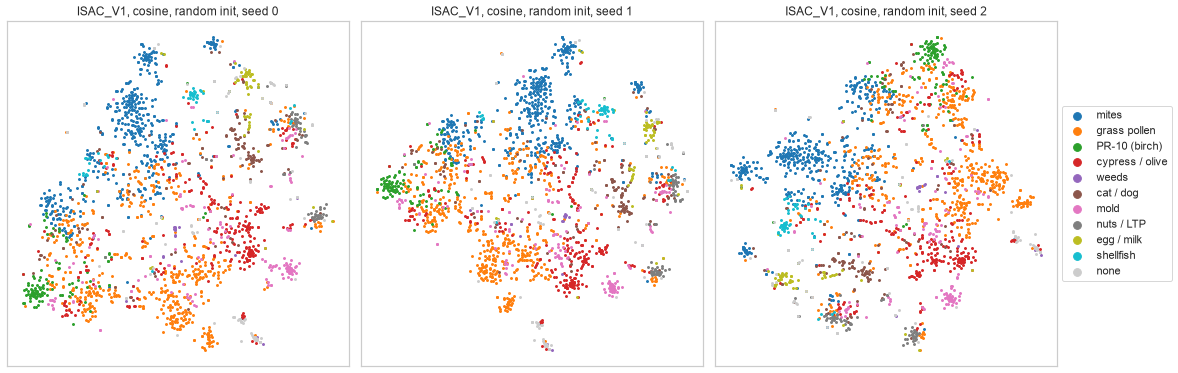

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, seed in zip(axes, [0, 1, 2]):
    plot_map(ax, seed_maps[seed], group["ISAC_V1"][profiles["ISAC_V1"].index],
             f"ISAC_V1, cosine, random init, seed {seed}", categorical=True)
axes[2].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4)
plt.tight_layout()
plt.show()

**Lecture du tableau** (5 graines, moyenne ± écart-type) :
- **la carte est fiable localement** : trustworthiness entre 0,91 et 0,96 avec la distance cosinus, avec des écarts-types d'environ 0,002 ;
- **la carte perd peu d'information de profil** : l'accord d'étiquette passe de 0,61–0,67 dans l'espace d'origine à 0,56–0,62 sur la carte, contre 0,17–0,18 par hasard. Comme l'étiquette est calculée à partir des mêmes IgE, un accord élevé est attendu : ce qui compte, c'est que la carte en conserve l'essentiel ;
- **cosinus contre euclidien** : le cosinus préserve mieux les voisinages (trustworthiness supérieure de 0,05 à 0,07 sur les trois puces), mais l'accord d'étiquette est presque le même (écart de 0 à 0,02). Sur les patients sensibilisés, les deux distances contiennent donc à peu près la même information de profil. L'avantage visuel du cosinus vient surtout du retrait du gradient d'intensité et des patients non sensibilisés.

Sur les cartes, l'orientation change d'une graine à l'autre (t-SNE n'a pas d'axe privilégié), mais les mêmes îlots se reforment : acariens, PR-10, crustacés, moisissures, œuf/lait, fruits à coque.

### 4.2 Perplexité

Une structure qui ne tient que pour une valeur de perplexité est suspecte. On refait la carte cosinus d'ISAC v1 (la plus grande puce) avec trois valeurs : 5 (voisinage très local), 30, et 100 (voisinage plus large).

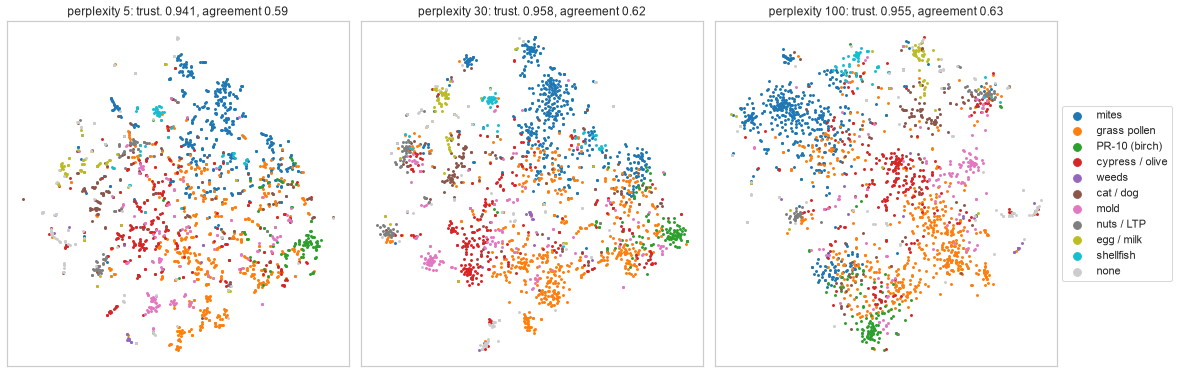

In [11]:
chip = "ISAC_V1"
x, labels = profiles[chip].to_numpy(), group[chip][profiles[chip].index]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, perplexity in zip(axes, [5, 30, 100]):
    emb = TSNE(perplexity=perplexity, metric="cosine", init="pca",
               random_state=SEED).fit_transform(x)
    tw = trustworthiness(x, emb, n_neighbors=K, metric="cosine")
    plot_map(ax, emb, labels, f"perplexity {perplexity}: trust. {tw:.3f}, "
             f"agreement {knn_agreement(emb, labels):.2f}", categorical=True)
axes[2].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4)
plt.tight_layout()
plt.show()

**Lecture.** À perplexité 5, la carte se fragmente en petits amas et l'accord baisse un peu (0,59). À 30 et 100, les mêmes grands ensembles apparaissent : un pôle acariens, un pôle pollens (graminées, cyprès/olivier), un îlot PR-10 et des petits groupes alimentaires. Trustworthiness et accord varient peu entre 30 et 100 : l'organisation n'est pas un artefact d'un réglage particulier.

## 5. Une carte commune aux trois puces

Pour analyser *tous* les patients ensemble, il faut un espace commun : les **91 allergènes présents sur les trois puces**, ramenés à **positif / négatif** (seuil 0,3) pour neutraliser les différences d'échelle entre puces.

La distance adaptée à des vecteurs binaires est la **distance de Jaccard** : la part d'allergènes positifs qui ne sont *pas* partagés entre deux patients.

Si la carte se découpe selon la puce, c'est que l'harmonisation ne suffit pas et qu'un effet technique (ou de recrutement) persiste.

91 shared allergens, 3398 sensitized patients


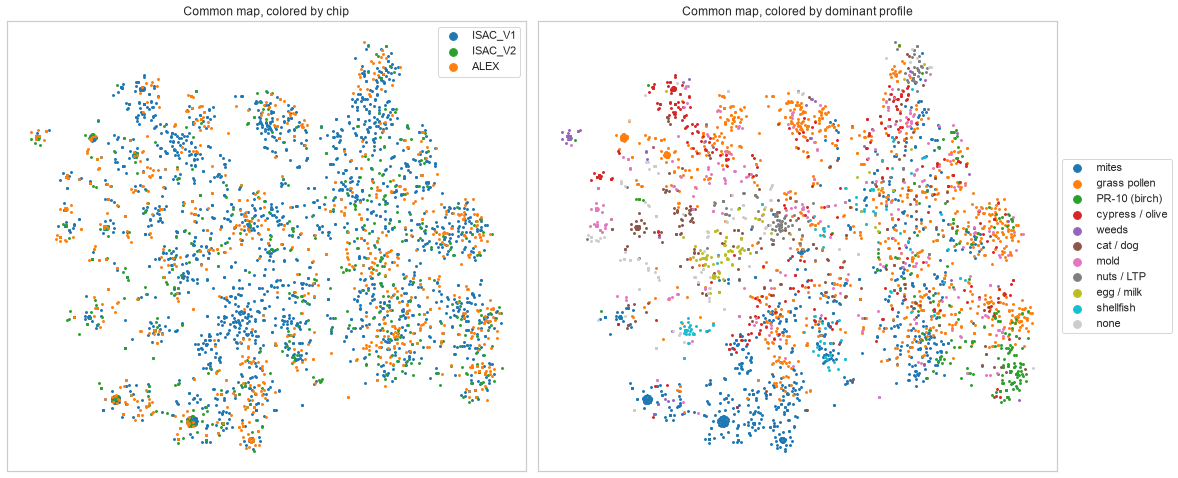

In [12]:
sub = df.loc[pd.concat([raw[c] for c in CHIPS]).index]
shared = [c for c in ige_cols if sub[c].notna().all()]
binary = sub[shared] >= THRESHOLD
binary = binary[binary.any(axis=1)]  # Jaccard is undefined for empty profiles

emb_common = TSNE(perplexity=30, metric="jaccard", init="pca",
                  random_state=SEED).fit_transform(binary.to_numpy(dtype=bool))

chip_of = df.loc[binary.index, "Chip_Type"]
group_all = pd.concat([group[c] for c in CHIPS]).loc[binary.index]
print(f"{len(shared)} shared allergens, {len(binary)} sensitized patients")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for c, color in zip(CHIPS, ["tab:blue", "tab:green", "tab:orange"]):
    mask = (chip_of == c).values
    axes[0].scatter(emb_common[mask, 0], emb_common[mask, 1], s=4, color=color, label=c)
axes[0].set_title("Common map, colored by chip")
axes[0].legend(markerscale=4)
axes[0].set_xticks([])
axes[0].set_yticks([])
plot_map(axes[1], emb_common, group_all, "Common map, colored by dominant profile",
         categorical=True)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4)
plt.tight_layout()
plt.show()

La carte de gauche donne l'impression d'un bon mélange, mais l'œil voit mal les petites différences. On mesure donc, pour chaque puce, la part des 15 voisins **qui viennent de la même puce**, dans l'espace d'origine (distance de Jaccard) et sur la carte. Sans aucun effet puce, cette part serait égale au poids de la puce dans l'échantillon.

In [13]:
def same_chip_share(x, metric):
    nn = NearestNeighbors(n_neighbors=K + 1, metric=metric).fit(x)
    idx = nn.kneighbors(x, return_distance=False)[:, 1:]
    chips = chip_of.to_numpy(dtype=object)
    same = chips[idx] == chips[:, None]
    return pd.Series(same.mean(axis=1), index=chip_of.index).groupby(chip_of).mean()


mixing = pd.DataFrame({
    "share of patients (no chip effect)": chip_of.value_counts(normalize=True),
    "same-chip neighbours, original space": same_chip_share(binary.to_numpy(dtype=bool), "jaccard"),
    "same-chip neighbours, map": same_chip_share(emb_common, "euclidean"),
}).loc[CHIPS]
mixing.round(2)

,share of patients (no chip effect),"same-chip neighbours, original space","same-chip neighbours, map"
Chip_Type,,,
ISAC_V1,0.60,0.67,0.66
ISAC_V2,0.16,0.21,0.19
ALEX,0.25,0.35,0.32


**Lecture.** Sur la carte de droite, la structure par profil se retrouve sur l'ensemble des patients : acariens en bas, pollens à droite, aliments (fruits à coque, œuf/lait, crustacés) au centre gauche. Les gros points sont des patients au profil binaire **strictement identique**, superposés (17 % des patients partagent leur profil exact avec au moins un autre).

Le tableau nuance l'impression de mélange de la carte de gauche : chaque puce a **plus de voisins de la même puce que ne le voudrait le hasard**, de +5 points (ISAC v2) à +10 points (ALEX), dans l'espace d'origine comme sur la carte. L'effet puce est donc **modéré mais réel**. On ne peut pas dire d'où il vient : technique (sensibilité de la puce), recrutement (centres, région) ou période, car ces facteurs sont confondus. Le cas cyprès/olivier en est un exemple : 12 % des patients ISAC v1, contre 0,7 % sur ISAC v2 et 3 % sur ALEX, très probablement pour une raison géographique.

## 6. Ce qu'on retient

**Ce que les résultats montrent**
- Avec la distance euclidienne, la carte reproduit la PCA : l'**intensité** domine, et les patients non sensibilisés forment un bloc.
- Sur les patients sensibilisés, la distance **cosinus** donne des cartes plus fidèles localement (trustworthiness 0,91–0,96 contre 0,87–0,90). Elles se lisent en deux régimes : des **îlots périphériques** de patients peu sensibilisés au profil pur (acariens, PR-10, moisissures, chat/chien, crustacés, œuf/lait, fruits à coque/LTP) et un **continuum central** de polysensibilisés.
- Cette organisation est **stable** sur 5 graines (écarts-types de 0,002 à 0,006) et pour des perplexités de 30 à 100.
- Une partie des îlots les plus serrés sont triviaux : 9 à 12 % des patients sensibilisés ont exactement le même ensemble d'allergènes positifs qu'un autre patient.
- Sur les 91 allergènes communs en positif/négatif, les trois puces se superposent largement, avec un **effet puce modéré** (+5 à +10 points de voisins de la même puce par rapport au hasard).

**Ce que cela suggère**
- Les profils « purs » sont de bons candidats pour des groupes cliniquement interprétables. Les polysensibilisés seront difficiles à découper en clusters durs : un score continu par famille de protéines, ou un clustering souple, sera sans doute mieux adapté.
- L'espace harmonisé (91 allergènes binaires) permet d'analyser tous les patients ensemble, à condition de garder `Chip_Type` comme covariable.

**Limites**
- t-SNE ne définit pas de clusters : les amas sont des indices, pas des groupes validés.
- L'étiquette « profil dominant » est une aide à la lecture, calculée à partir des mêmes IgE : l'accord élevé avec la carte est en partie mécanique.
- Puce, centre, région et période sont confondus : aucun effet puce ne peut être attribué à la technique seule.

**Pour la suite**
- Faire le clustering dans l'**espace d'origine** (Jaccard ou cosinus), mesurer sa stabilité par bootstrap, puis n'utiliser t-SNE que pour visualiser le résultat.
- Croiser ensuite ces groupes avec les données cliniques (traitement de l'asthme, rhinite, dermatite).